In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# Check hardware acceleration
print("TensorFlow Version:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("GPUs Available:", len(gpus), "->", gpus if gpus else "Running on CPU")

TensorFlow Version: 2.21.0
GPUs Available: 0 -> Running on CPU


In [ ]:
# Load dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values from [0, 255] to [0.0, 1.0]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Reshape to include channel dimension (28, 28, 1)
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print(f"Training data shape: {x_train.shape}, Labels: {y_train.shape}")
print(f"Testing data shape:  {x_test.shape}, Labels: {y_test.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28, 1), Labels: (60000,)
Testing data shape:  (10000, 28, 28, 1), Labels: (10000,)


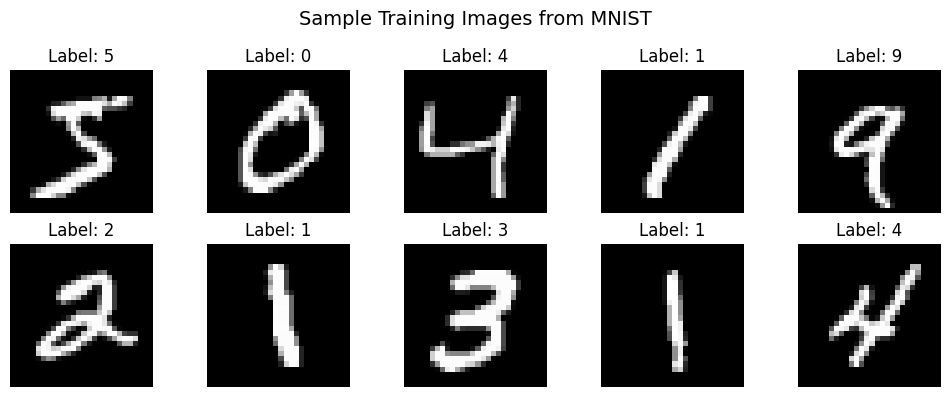

In [ ]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.suptitle("Sample Training Images from MNIST", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
def build_mnist_cnn(input_shape=(28, 28, 1), num_classes=10):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        # In-model Data Augmentation to enhance generalization
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.08),

        # Block 1
        layers.Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),

        # Block 2
        layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),

        # Dense Classifier Head
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_mnist_cnn()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 469,098 (1.79 MB)

 Trainable params: 468,458 (1.79 MB)

 Non-trainable params: 640 (2.50 KB)

In [ ]:
lr_scheduler = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-5,
    verbose=1
)

early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True,
    verbose=1
)

batch_size = 128
epochs = 12

history = model.fit(
    x_train, y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.1,
    callbacks=[lr_scheduler, early_stopping],
    verbose=1
)

Epoch 1/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 296s 689ms/step - accuracy: 0.9242 - loss: 0.2452 - val_accuracy: 0.9110 - val_loss: 0.3244 - learning_rate: 0.0010
Epoch 2/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 312s 666ms/step - accuracy: 0.9699 - loss: 0.0958 - val_accuracy: 0.9875 - val_loss: 0.0411 - learning_rate: 0.0010
Epoch 3/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 274s 651ms/step - accuracy: 0.9770 - loss: 0.0737 - val_accuracy: 0.9912 - val_loss: 0.0289 - learning_rate: 0.0010
Epoch 4/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 273s 648ms/step - accuracy: 0.9802 - loss: 0.0636 - val_accuracy: 0.9920 - val_loss: 0.0310 - learning_rate: 0.0010
Epoch 5/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 327s 660ms/step - accuracy: 0.9822 - loss: 0.0591 - val_accuracy: 0.9908 - val_loss: 0.0285 - learning_rate: 0.0010
Epoch 6/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 273s 648ms/step - accuracy: 0.9839 - loss: 0.0535 - val_accuracy: 0.9918 - val_loss: 0.0267 - learning_rate: 0.0010
Epoch 7/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 275s 652ms/step - accura

## Step 6: Testing & Performance Evaluation

Final Test Loss:     0.0181
Final Test Accuracy: 99.38%


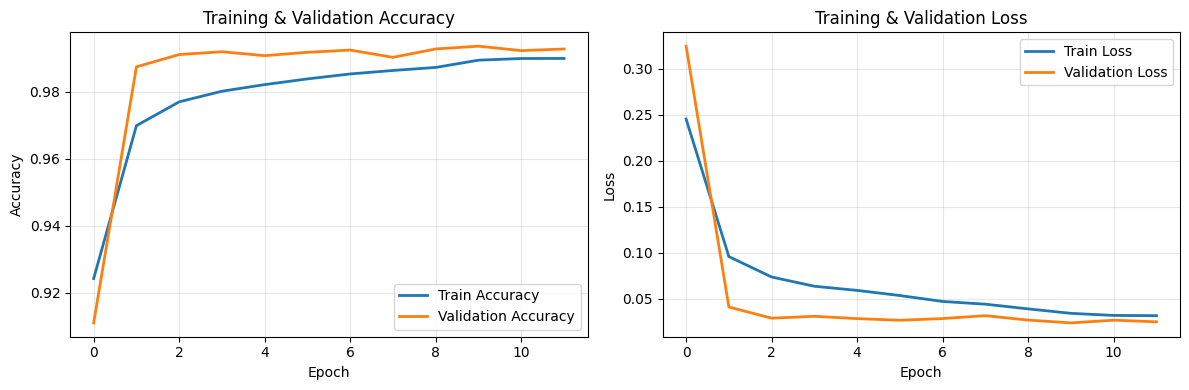

In [ ]:
# Evaluate on the untouched 10,000 test set
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Final Test Loss:     {test_loss:.4f}")
print(f"Final Test Accuracy: {test_acc * 100:.2f}%")

# Learning Curves (Loss & Accuracy)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', lw=2)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', lw=2)
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', lw=2)
plt.plot(history.history['val_loss'], label='Validation Loss', lw=2)
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 40ms/step
=== Detailed Classification Report ===

              precision    recall  f1-score   support

           0     0.9980    0.9980    0.9980       980
           1     0.9956    0.9956    0.9956      1135
           2     0.9961    0.9942    0.9952      1032
           3     0.9892    0.9980    0.9936      1010
           4     0.9919    0.9959    0.9939       982
           5     0.9877    0.9933    0.9905       892
           6     0.9979    0.9864    0.9921       958
           7     0.9865    0.9951    0.9908      1028
           8     0.9979    0.9938    0.9959       974
           9     0.9970    0.9871    0.9920      1009

    accuracy                         0.9938     10000
   macro avg     0.9938    0.9937    0.9938     10000
weighted avg     0.9938    0.9938    0.9938     10000



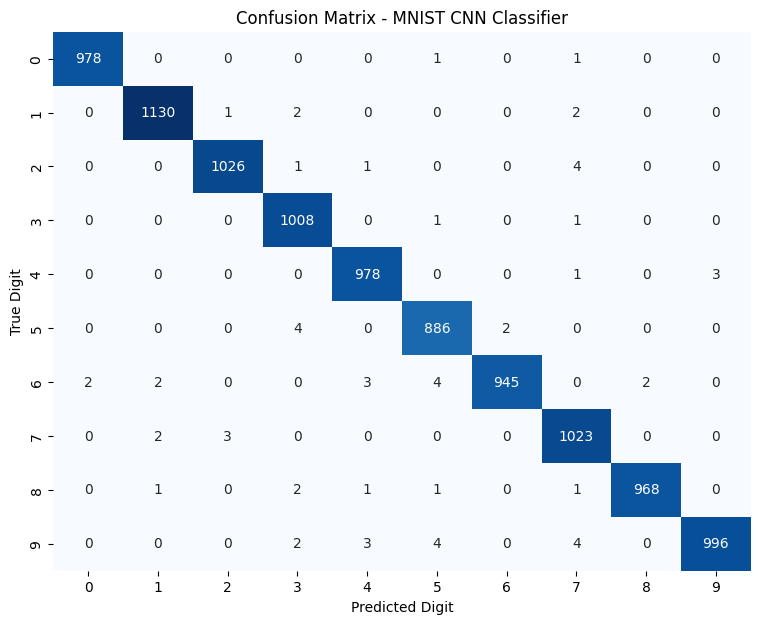

In [ ]:
y_pred_probs = model.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print("=== Detailed Classification Report ===\n")
print(classification_report(y_test, y_pred, digits=4))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix - MNIST CNN Classifier')
plt.xlabel('Predicted Digit')
plt.ylabel('True Digit')
plt.show()

Total Misclassified Samples: 62 out of 10000


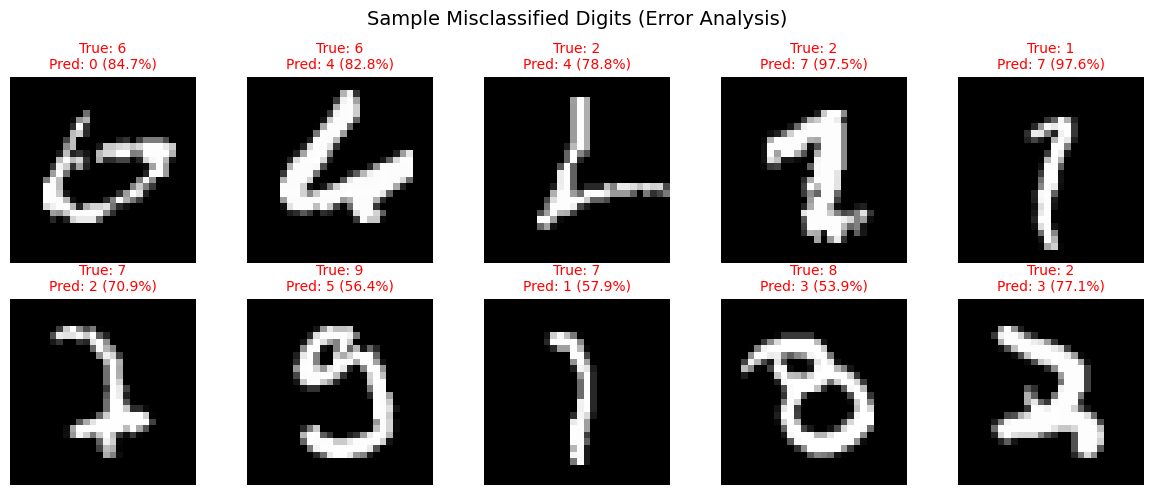

In [ ]:
# Identify misclassified indices
misclassified_indices = np.where(y_pred != y_test)[0]
print(f"Total Misclassified Samples: {len(misclassified_indices)} out of {len(y_test)}")

# Plot first 10 misclassified examples
plt.figure(figsize=(12, 5))
for i, idx in enumerate(misclassified_indices[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx].squeeze(), cmap='gray')
    confidence = y_pred_probs[idx][y_pred[idx]] * 100
    plt.title(f"True: {y_test[idx]}\nPred: {y_pred[idx]} ({confidence:.1f}%)", color='red', fontsize=10)
    plt.axis('off')

plt.suptitle("Sample Misclassified Digits (Error Analysis)", fontsize=14)
plt.tight_layout()
plt.show()